# 1. Gaussian Discriminant Analysis — Iris Dataset


### Import Numerical, Plotting, and PCA Libraries


In [1]:
from sklearn import datasets
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

### Load Iris Features and Project onto Two Principal Components


In [2]:
iris = datasets.load_iris()
Xorig = iris.data
y = iris.target
pca = PCA(n_components=2)
X = pca.fit(Xorig).transform(Xorig)

### Optional: Plot All Iris Samples in PCA Space


In [6]:
# plt.scatter(X[:, 0], X[:, 1], marker='o', c=y, edgecolor='k')

### Optional: Plot the Two Overlapping Iris Classes


In [5]:
# plt.scatter(X[50:150, 0], X[50:150,  1], marker='o', c=y[50:150], edgecolor='k');

## 1.1 Estimate Class Means and Shared Covariance


### Compute Per-Class Means and Pooled Covariance


In [39]:
def pooled_covariance_estimator(X, y, classes):
  mus = []
  sigmas = []
  N_total = 0
  covariance_sum = np.zeros((X.shape[1], X.shape[1]))

  for c in classes:
    Xc = X[y == c]
    Nc = Xc.shape[0]
    N_total += Nc

    mu_c = np.mean(Xc, axis=0)
    mus.append(mu_c)

    covariance_sum += (Xc - mu_c).T @ (Xc - mu_c)


  Sigma = covariance_sum / N_total

  return Sigma, mus

### Inspect Two-Class Mean Vectors and Covariance


In [8]:
sigma_pooled, mu = pooled_covariance_estimator(X,y,[1,2])

print(f"Mean Vector for Class 2:\n{mu[0]}")
print(f"\nMean Vector for Class 3:\n{mu[1]}")
print(f"\nPooled Covariance Matrix:\n{sigma_pooled}")

Mean Vector for Class 2:
[ 0.53320657 -0.24554983]

Mean Vector for Class 3:
[2.10920889 0.05466479]

Pooled Covariance Matrix:
[[0.41834394 0.23255254]
 [0.23255254 0.20504771]]


## 1.2 Define the Linear Discriminant Score


### Implement the LDA Discriminant Function


In [9]:
def discriminant_function(x, mu, Sigma, prior=0.5):
  Sigma_inv = np.linalg.inv(Sigma)

  term1 = x @ Sigma_inv @ mu
  term2 = -0.5 * (mu.T @ Sigma_inv @ mu)
  term3 = np.log(prior)

  return term1 + term2 + term3

## 1.3 Visualize Two-Class LDA Decision Regions


### Build LDA Decision Regions on a Two-Dimensional Grid


In [10]:
def plot_multiclass_decision_regions(X, y, classes, priors=None):
  K = len(classes)

  Sigma, mus = pooled_covariance_estimator(X, y, classes)

  if priors is None:
    priors = np.full(K, 1.0 / K)

  x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1
  y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1

  xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
    )
  grid = np.c_[xx.ravel(), yy.ravel()]

  g_values = np.zeros((grid.shape[0], K))

  for k in range(K):
    g_values[:, k] = discriminant_function(grid, mus[k], Sigma, priors[k])

  region_assignments = np.argmax(g_values, axis=1)
  regions = region_assignments.reshape(xx.shape)

  plt.figure(figsize=(7, 6))
  plt.contourf(xx, yy, regions, alpha=0.3)

  for idx, c in enumerate(classes):
    plt.scatter(
      X[y == c, 0],
      X[y == c, 1],
      edgecolor='k',
      label=f"Class {c}"
      )

  plt.xlabel("PC1")
  plt.ylabel("PC2")
  plt.title("Multiclass LDA Decision Regions")
  plt.legend()
  plt.tight_layout()
  plt.show()

### Plot LDA Classification Regions for Classes 1 and 2


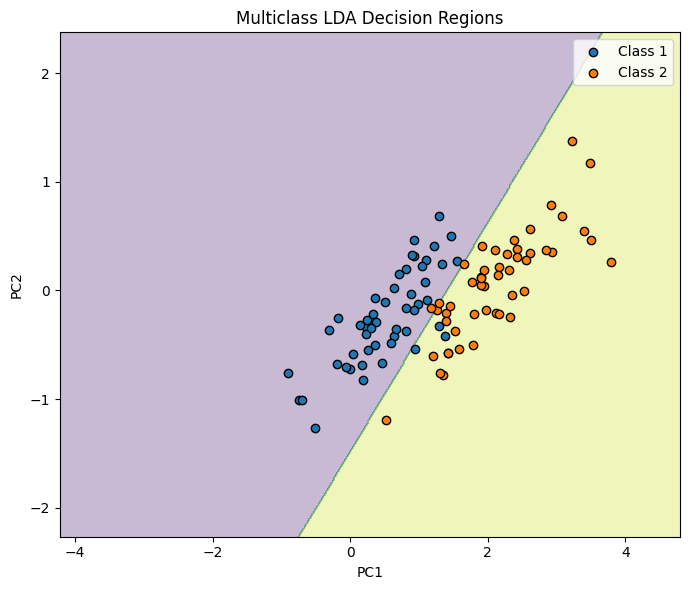

In [11]:
plot_multiclass_decision_regions(X, y, [1,2])

## 1.4 Derive and Plot Pairwise Linear Decision Boundaries


### Calculate Linear Decision Boundary Coefficients


In [12]:
def compute_all_pairwise_boundaries(Sigma, mus, priors=None):
  K = len(mus)
  Sigma_inv = np.linalg.inv(Sigma)

  if priors is None:
    priors = np.full(K, 1 / K)

  boundaries = {}

  for i in range(K):
    for j in range(i + 1, K):
      mu_i = mus[i]
      mu_j = mus[j]
      pi_i = priors[i]
      pi_j = priors[j]

      # w_ij
      w = Sigma_inv @ (mu_i - mu_j)

      # w0_ij
      w0 = (-0.5 * (mu_i @ Sigma_inv @ mu_i - mu_j @ Sigma_inv @ mu_j) + np.log(pi_i / pi_j))

      boundaries[(i, j)] = (w, w0)

  return boundaries

### Overlay Pairwise Boundaries on LDA Regions


In [15]:
def plot_multiclass_regions_with_boundaries(X, y, classes, priors=None):
  K = len(classes)

  Sigma, mus = pooled_covariance_estimator(X, y, classes)

  if priors is None:
    priors = np.full(K, 1 / K)

  x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1
  y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1

  xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
    )
  grid = np.c_[xx.ravel(), yy.ravel()]

  g_values = np.zeros((grid.shape[0], K))

  for k in range(K):
    g_values[:, k] = discriminant_function(grid, mus[k], Sigma, priors[k])

  regions = np.argmax(g_values, axis=1).reshape(xx.shape)

  plt.figure(figsize=(8, 6))
  plt.contourf(xx, yy, regions, alpha=0.3)

  for idx, c in enumerate(classes):
    plt.scatter(X[y == c, 0], X[y == c, 1], edgecolor='k', label=f"Class {c}")

  boundaries = compute_all_pairwise_boundaries(Sigma, mus, priors)

  x_line = np.linspace(x_min, x_max, 400)

  for (i, j), (w, w0) in boundaries.items():
    w1, w2 = w

    y_line = -(w1 / w2) * x_line - (w0 / w2)

    mask = (y_line >= y_min) & (y_line <= y_max)

    plt.plot(
        x_line[mask],
        y_line[mask],
        linewidth=2,
        label=f"Boundary {i} vs {j}"
        )

  plt.title("Multiclass LDA Decision Regions + Pairwise Boundaries")
  plt.xlabel("PC1")
  plt.ylabel("PC2")
  plt.legend()
  plt.tight_layout()
  plt.show()

### Visualize the Two-Class Boundary


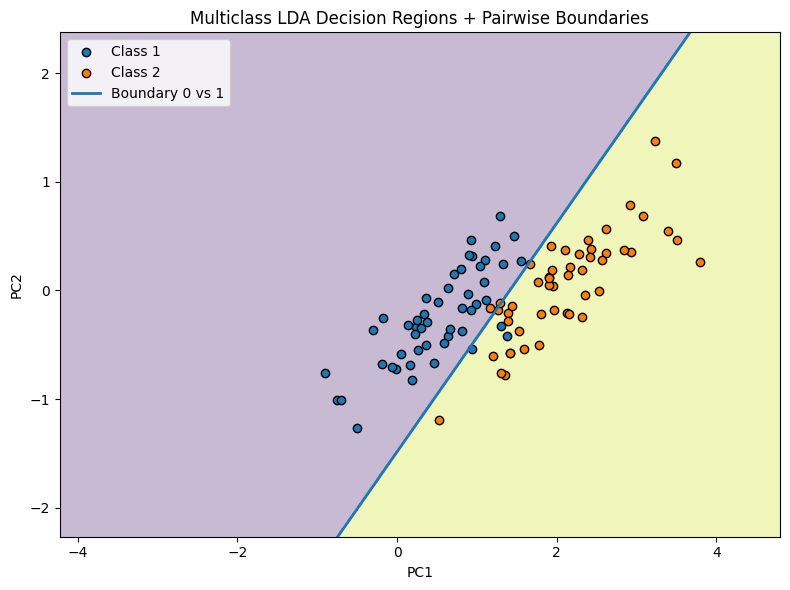

In [14]:
plot_multiclass_regions_with_boundaries(X, y, [1,2])

## 1.5 Investigate the Effect of Class Priors


### Define the Class-Prior Comparison Plot


In [16]:
def compare_two_priors(X, y, classes, priors):
  plt.figure(figsize=(12, 5))

  plot_multiclass_regions_with_boundaries(X, y, classes, priors[0])
  plot_multiclass_regions_with_boundaries(X, y, classes, priors[1])

  plt.tight_layout()

### Compare Equal and Unequal Class Priors


<Figure size 1200x500 with 0 Axes>

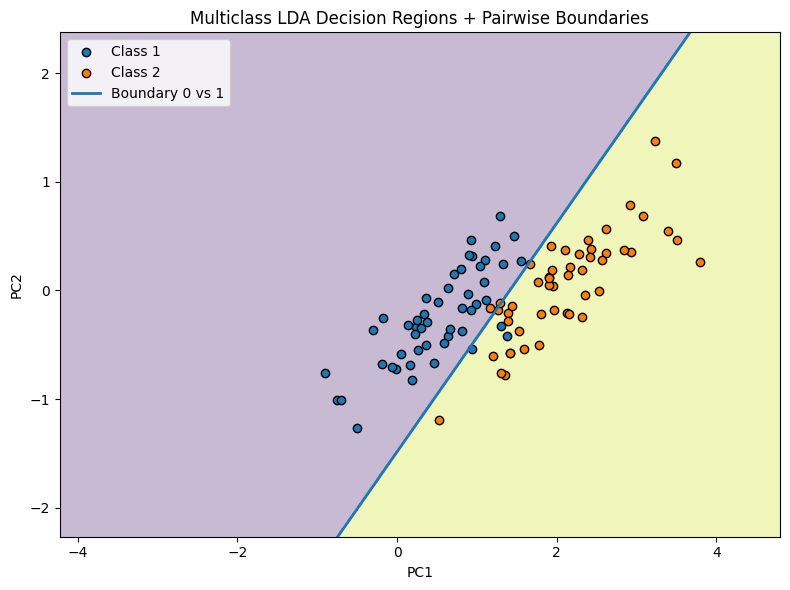

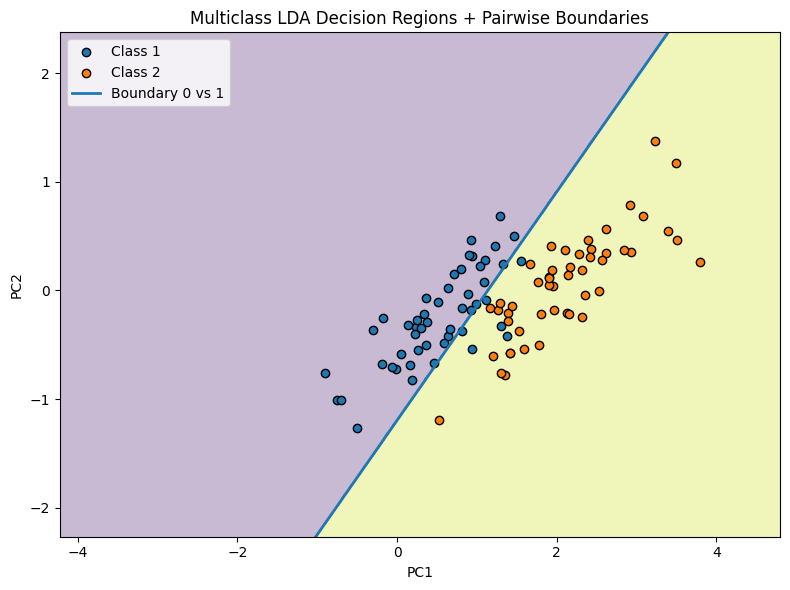

<Figure size 640x480 with 0 Axes>

In [17]:
compare_two_priors(X, y, [1,2], [[0.5,0.5],[0.1,0.9]])

## 1.6 Extend LDA to Three Iris Classes


### Estimate Three-Class Shared Covariance and Means


In [18]:
sigma_pooled, mu = pooled_covariance_estimator(X,y,[0,1,2])

print(f"Mean Vector for Class 1:\n{mu[0]}")
print(f"\nMean Vector for Class 2:\n{mu[1]}")
print(f"\nMean Vector for Class 3:\n{mu[2]}")
print(f"\nPooled Covariance Matrix:\n{sigma_pooled}")

Mean Vector for Class 1:
[-2.64241546  0.19088505]

Mean Vector for Class 2:
[ 0.53320657 -0.24554983]

Mean Vector for Class 3:
[2.10920889 0.05466479]

Pooled Covariance Matrix:
[[0.2949098  0.17334231]
 [0.17334231 0.20781292]]


### Visualize Three-Class LDA Decision Regions


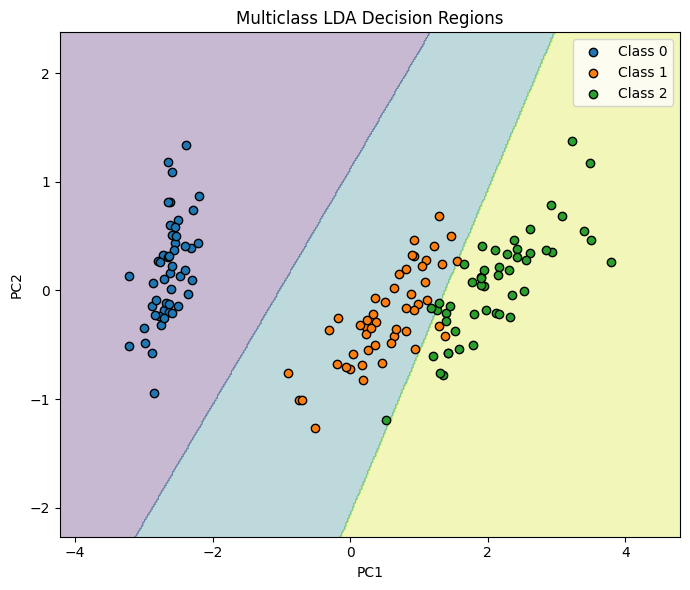

In [19]:
plot_multiclass_decision_regions(X, y, [0,1,2])

### Estimate Class-Specific Covariances and Priors for QDA


In [20]:
def classwise_covariance_estimator(X, y):
  classes = np.unique(y)
  K = len(classes)

  mus = []
  Sigmas = []
  priors = []

  N_total = X.shape[0]

  for c in classes:
    Xc = X[y == c]
    Nc = Xc.shape[0]

    mu_c = np.mean(Xc, axis=0)

    diff = Xc - mu_c
    Sigma_c = (diff.T @ diff) / Nc

    mus.append(mu_c)
    Sigmas.append(Sigma_c)
    priors.append(Nc / N_total)

  return Sigmas, mus, priors, classes

### Inspect the Three Class-Specific Covariance Matrices


In [21]:
sigmas, mus, priors, classes = classwise_covariance_estimator(X,y)

print(f"Mean Vector for Class 1:\n{mus[0]}")
print(f"\nMean Vector for Class 2:\n{mus[1]}")
print(f"\nMean Vector for Class 3:\n{mus[2]}")
print(f"\nPooled Covariance Matrix:\n{sigmas[0]}")
print(f"\nPooled Covariance Matrix:\n{sigmas[1]}")
print(f"\nPooled Covariance Matrix:\n{sigmas[2]}")

Mean Vector for Class 1:
[-2.64241546  0.19088505]

Mean Vector for Class 2:
[ 0.53320657 -0.24554983]

Mean Vector for Class 3:
[2.10920889 0.05466479]

Pooled Covariance Matrix:
[[0.0480415  0.05492185]
 [0.05492185 0.21334336]]

Pooled Covariance Matrix:
[[0.34836155 0.19476732]
 [0.19476732 0.18146878]]

Pooled Covariance Matrix:
[[0.48832634 0.27033776]
 [0.27033776 0.22862663]]


## 1.7 Subsample the Iris Data and Study QDA with Rejection


### Draw a Reproducible 80% Iris Subsample


In [32]:
np.random.seed(54)

n_samples = int(0.8 * len(X))
subset_indices = np.random.choice(len(X), size=n_samples, replace=False)

X_subset = X[subset_indices]
y_subset = y[subset_indices]

print(f"Original dataset shape: {X.shape}")
print(f"80% subset shape: {X_subset.shape}")
print(f"Class distribution in subset: {np.bincount(y_subset)}")

Original dataset shape: (150, 2)
80% subset shape: (120, 2)
Class distribution in subset: [38 40 42]


### Estimate LDA Parameters on the 80% Subsample


In [41]:
sigma_pooled_80, mu_80 = pooled_covariance_estimator(X_subset,y_subset,[0,1,2])

print(f"Mean Vector for Class 1:\n{mu_80[0]}")
print(f"\nMean Vector for Class 2:\n{mu_80[1]}")
print(f"\nMean Vector for Class 3:\n{mu_80[2]}")
print(f"\nPooled Covariance Matrix:\n{sigma_pooled_80}")

Mean Vector for Class 1:
[-2.65290252  0.21403289]

Mean Vector for Class 2:
[ 0.57742361 -0.23736745]

Mean Vector for Class 3:
[2.04207856 0.02296892]

Pooled Covariance Matrix:
[[0.28390469 0.16228382]
 [0.16228382 0.19809826]]


### Plot LDA Regions for the 80% Subsample


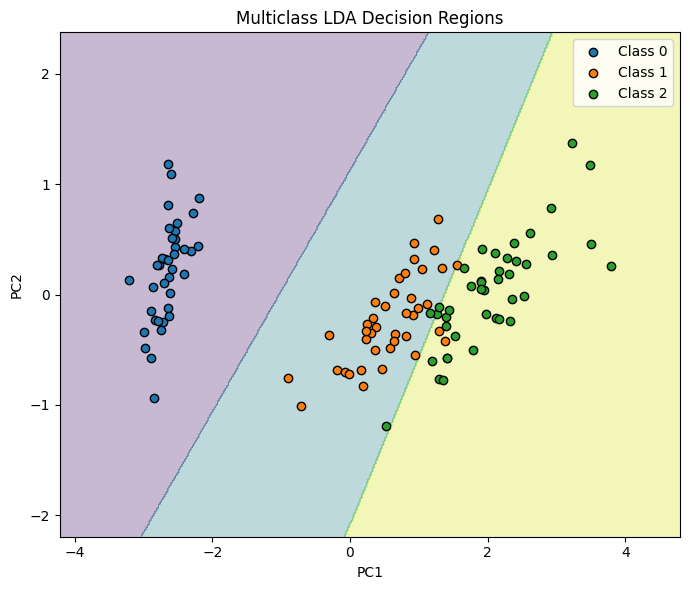

In [42]:
plot_multiclass_decision_regions(X_subset,y_subset,[0,1,2])

### Estimate QDA Parameters on the 80% Subsample


In [43]:
sigmas_80, mus_80, priors_80, classes_80 = classwise_covariance_estimator(X_subset,y_subset)

print(f"Mean Vector for Class 1:\n{mus_80[0]}")
print(f"\nMean Vector for Class 2:\n{mus_80[1]}")
print(f"\nMean Vector for Class 3:\n{mus_80[2]}")
print(f"\nPooled Covariance Matrix:\n{sigmas_80[0]}")
print(f"\nPooled Covariance Matrix:\n{sigmas_80[1]}")
print(f"\nPooled Covariance Matrix:\n{sigmas_80[2]}")

Mean Vector for Class 1:
[-2.65290252  0.21403289]

Mean Vector for Class 2:
[ 0.57742361 -0.23736745]

Mean Vector for Class 3:
[2.04207856 0.02296892]

Pooled Covariance Matrix:
[[0.04491638 0.05607755]
 [0.05607755 0.20521652]]

Pooled Covariance Matrix:
[[0.30047472 0.15059197]
 [0.15059197 0.14917175]]

Pooled Covariance Matrix:
[[0.48435121 0.26951029]
 [0.26951029 0.23825462]]


### Implement the QDA Discriminant Score


In [44]:
def qda_discriminant(X, mu_k, Sigma_k, prior_k):
  X = np.atleast_2d(X)
  Sigma_inv = np.linalg.inv(Sigma_k)
  diff = X - mu_k
  quad = -0.5 * np.sum((diff @ Sigma_inv) * diff, axis=1)
  logdet = -0.5 * np.log(np.linalg.det(Sigma_k))
  logprior = np.log(prior_k)
  return quad + logdet + logprior

### Convert QDA Scores into Posterior Probabilities


In [27]:
def qda_posteriors(X, mus, Sigmas, priors):
  K = len(mus)
  N = X.shape[0]

  g = np.zeros((N, K))
  for k in range(K):
    g[:, k] = qda_discriminant(X, mus[k], Sigmas[k], priors[k])

  g = g - np.max(g, axis=1, keepdims=True)
  post = np.exp(g)
  post = post / np.sum(post, axis=1, keepdims=True)
  return post

### Apply Posterior-Threshold Rejection


In [28]:
def classify_with_rejection(X, mus, Sigmas, priors, lam):
  post = qda_posteriors(X, mus, Sigmas, priors)
  max_post = np.max(post, axis=1)
  best_class = np.argmax(post, axis=1)

  reject = max_post < (1 - lam)

  labels = best_class.copy()
  labels[reject] = -1
  return labels

### Visualize QDA Decision and Rejection Regions


In [29]:
def plot_qda_with_rejection(X, y, lam):
  Sigmas, mus, priors, classes = classwise_covariance_estimator(X, y)

  x_min, x_max = X[:,0].min()-1, X[:,0].max()+1
  y_min, y_max = X[:,1].min()-1, X[:,1].max()+1

  xx, yy = np.meshgrid(
      np.linspace(x_min, x_max, 400),
      np.linspace(y_min, y_max, 400)
      )
  grid = np.c_[xx.ravel(), yy.ravel()]

  labels = classify_with_rejection(grid, mus, Sigmas, priors, lam)
  regions = labels.reshape(xx.shape)

  plt.figure(figsize=(7,6))
  plt.contourf(xx, yy, regions, alpha=0.35)

  for idx, c in enumerate(classes):
    plt.scatter(X[y==c,0], X[y==c,1], edgecolor='k', label=f"Class {c}")

  plt.title(f"QDA Regions with Rejection (λ={lam})")
  plt.xlabel("PC1")
  plt.ylabel("PC2")
  plt.legend()
  plt.tight_layout()
  plt.show()

### Plot QDA Rejection Regions at λ = 0.2


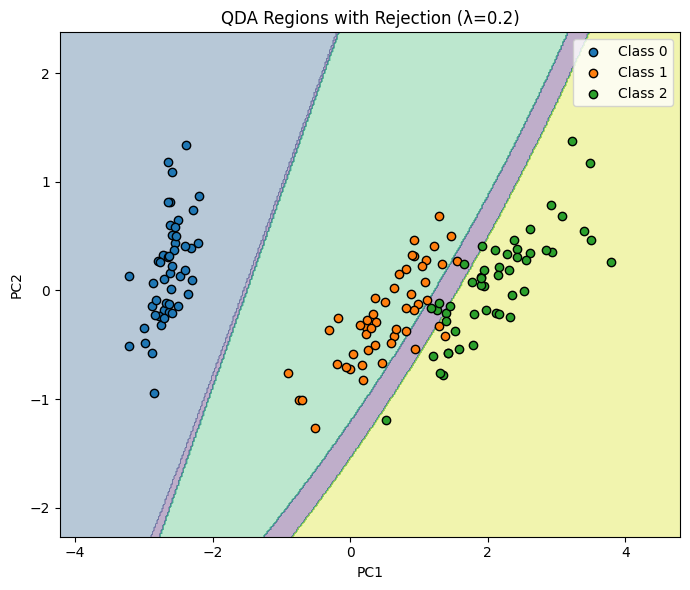

In [45]:
plot_qda_with_rejection(X, y, lam=0.2)
# plot_qda_with_rejection(X, y, lam=0.4)
# plot_qda_with_rejection(X, y, lam=0.9)

# 2. Gaussian Naive Bayes — Numerical Classification


### Import MATLAB Dataset Reader


In [46]:
from scipy.io import loadmat

## 2.1 Estimate Class Prior Probabilities


### Compute Empirical Class Priors


In [47]:
def prior(yTrain):
  classes = np.unique(yTrain)
  K = len(classes)
  p = np.zeros(K)

  for idx, c in enumerate(classes):
    p[idx] = np.sum(yTrain == c) / len(yTrain)

  return p, classes

## 2.2 Estimate Class-Conditional Gaussian Parameters


### Estimate Gaussian Means and Variances per Feature and Class


In [48]:
def likelihood(xTrain, yTrain):
  m = xTrain.shape[1]
  classes = np.unique(yTrain)
  K = len(classes)

  M = np.zeros((m, K))
  V = np.zeros((m, K))

  for idx, c in enumerate(classes):
    Xc = xTrain[yTrain == c]
    M[:, idx] = Xc.mean(axis=0)
    V[:, idx] = Xc.var(axis=0)

  return M, V, classes

### Implement the Univariate Gaussian Log-Likelihood


In [49]:
def gaussian_logpdf(x, mean, var):
  return -0.5*np.log(2*np.pi*var) - (x-mean)**2/(2*var)

## 2.3 Predict Classes Using Log Posterior Scores


### Classify Test Samples with Gaussian Naive Bayes


In [50]:
def naiveBayesClassify(xTest, M, V, p, classes):
  N, m = xTest.shape
  K = len(classes)
  logpost = np.zeros((N, K))

  for k in range(K):
    log_prior = np.log(p[k])
    log_likelihood = gaussian_logpdf(xTest, M[:,k], V[:,k]).sum(axis=1)
    logpost[:,k] = log_prior + log_likelihood

  class_idx = np.argmax(logpost, axis=1)
  return classes[class_idx]

## 2.4 Evaluate Predictions with Accuracy, Precision, and Recall


### Compute One-vs-Rest Precision and Recall


In [51]:
def precision_recall(yTest, yPred, c):
  TP = np.sum((yPred == c) & (yTest == c))
  FP = np.sum((yPred == c) & (yTest != c))
  FN = np.sum((yPred != c) & (yTest == c))

  precision = 0
  recall = 0

  if TP + FP > 0:
    precision = TP / (TP + FP)
  if TP + FN > 0:
    recall = TP / (TP + FN)

  return precision, recall

### Evaluate the Classifier and Write Metrics to a Text File


In [52]:
def evaluate(yTest, yPred):
  acc = np.mean(yTest == yPred)

  prec_rec = []
  for i in range(5):
    prec_rec.append(precision_recall(yTest, yPred, i+1))

  with open("evaluation.txt", "w") as f:
    f.write(f"{acc:.3f}\n")
    f.write(f"{prec_rec[0][0]:.3f}\n")
    f.write(f"{prec_rec[0][1]:.3f}\n")
    f.write(f"{prec_rec[4][0]:.3f}\n")
    f.write(f"{prec_rec[4][1]:.3f}\n")

  return acc, prec_rec

### Load MATLAB Data, Train Classifier, and Report Metrics


In [59]:
data = loadmat("./guassianBayes.mat")
xTrain = data["xTrain"]
yTrain = data["yTrain"].ravel()
xTest  = data["xTest"]
yTest  = data["yTest"].ravel()

p, classes = prior(yTrain)
M, V, classes2 = likelihood(xTrain, yTrain)

yPred = naiveBayesClassify(xTest, M, V, p, classes)

acc, prec_rec = evaluate(yTest, yPred)

print("Accuracy:", acc)
print("Precision class 1:", prec_rec[0][0])
print("Recall class 1:", prec_rec[0][1])
print("Precision class 5:", prec_rec[4][0])
print("Recall class 5:", prec_rec[4][1])

Accuracy: 0.8348623853211009
Precision class 1: 0.9512195121951219
Recall class 1: 0.975
Precision class 5: 0.875
Recall class 5: 0.7777777777777778


---


# 3. Multinomial Naive Bayes — Baseball vs. Hockey


### Load Baseball and Hockey Bag-of-Words Matrices


In [3]:
base_train = np.loadtxt("baseball_train_set.csv", delimiter=",")
hock_train = np.loadtxt("hockey_train_set.csv", delimiter=",")

base_test  = np.loadtxt("baseball_test_set.csv", delimiter=",")
hock_test  = np.loadtxt("hockey_test_set.csv", delimiter=",")

### Combine Class-Specific Training and Test Sets


In [9]:
X_train = np.vstack([base_train, hock_train])
y_train = np.array([0]*50 + [1]*50)

X_test = np.vstack([base_test, hock_test])
y_test = np.array([0]*50 + [1]*50)

## 3.1 Estimate Word Probabilities by Maximum Likelihood


### Fit Multinomial Naive Bayes with MLE Word Probabilities


In [10]:
def train_multinomial_nb_mle(X_train, y_train):
  classes = np.unique(y_train)
  C = len(classes)
  V = X_train.shape[1]

  theta = np.zeros((C, V))

  for c in classes:
    Xc = X_train[y_train == c]
    word_counts = Xc.sum(axis=0)
    total = word_counts.sum()

    theta[c] = word_counts / total

  return theta

### Add an Epsilon to Safely Evaluate Log Probabilities


In [11]:
def safe_log(x):
  return np.log(x + 1e-12)

### Calculate a Document’s Multinomial Log Score


In [12]:
def log_probability(x, theta):
  return (x * safe_log(theta)).sum()

### Predict Baseball or Hockey Using Class Log Scores


In [13]:
def predict_nb_mle(X_test, theta):
  preds = []

  for x in X_test:
    log_base = log_probability(x, theta[0])
    log_hock = log_probability(x, theta[1])

    if log_base > log_hock:
      preds.append(0)
    elif log_hock > log_base:
      preds.append(1)
    else:
      preds.append(0)

  return np.array(preds)

### Evaluate the Unsmoothed Multinomial Classifier


In [14]:
theta = train_multinomial_nb_mle(X_train, y_train)
y_pred = predict_nb_mle(X_test, theta)

accuracy = np.mean(y_pred == y_test)
print("Test accuracy:", accuracy)
print("Predictions:", y_pred)

Test accuracy: 0.86
Predictions: [0 0 1 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0
 1 0 0 0 1 1 0 0 0 0 0 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


## 3.2 Apply Additive Smoothing and Sweep Its Strength


### Estimate Smoothed Word Probabilities


In [15]:
def train_multinomial_nb_map(X_train, y_train, beta):

  classes = np.unique(y_train)
  C = len(classes)
  V = X_train.shape[1]

  theta = np.zeros((C, V))

  for c in classes:
    Xc = X_train[y_train == c]
    word_counts = Xc.sum(axis=0)
    total = word_counts.sum()
    theta[c] = (word_counts + beta) / (total + beta * V)

  return theta

### Search Smoothing Strengths Between 0.2 and 0.5


In [ ]:
for b in np.linspace(0.2, 0.5, 20):
  theta = train_multinomial_nb_map(X_train, y_train, b)
  y_pred = predict_nb_mle(X_test, theta)
  print("beta:", b, "->", "accuracy:", np.mean(y_pred == y_test))

beta: 0.2 -> accuracy: 0.87
beta: 0.21578947368421053 -> accuracy: 0.88
beta: 0.23157894736842105 -> accuracy: 0.88
beta: 0.2473684210526316 -> accuracy: 0.88
beta: 0.26315789473684215 -> accuracy: 0.89
beta: 0.2789473684210526 -> accuracy: 0.89
beta: 0.2947368421052632 -> accuracy: 0.89
beta: 0.3105263157894737 -> accuracy: 0.88
beta: 0.3263157894736842 -> accuracy: 0.88
beta: 0.34210526315789475 -> accuracy: 0.88
beta: 0.35789473684210527 -> accuracy: 0.88
beta: 0.37368421052631584 -> accuracy: 0.88
beta: 0.3894736842105263 -> accuracy: 0.88
beta: 0.4052631578947369 -> accuracy: 0.88
beta: 0.4210526315789474 -> accuracy: 0.88
beta: 0.4368421052631579 -> accuracy: 0.88
beta: 0.45263157894736844 -> accuracy: 0.88
beta: 0.46842105263157896 -> accuracy: 0.88
beta: 0.4842105263157895 -> accuracy: 0.87
beta: 0.5 -> accuracy: 0.87


## 3.3 Compare Smoothing Values and Plot Test Accuracy


### Measure and Plot Accuracy Across Smoothing Values


beta=0, accuracy=0.8600
beta=1e-08, accuracy=0.8600
beta=1e-06, accuracy=0.8600
beta=0.001, accuracy=0.8600
beta=0.01, accuracy=0.8700
beta=0.1, accuracy=0.8700
beta=0.278, accuracy=0.8900
beta=1, accuracy=0.7900
beta=2, accuracy=0.6500
beta=5, accuracy=0.5500
beta=10, accuracy=0.5400


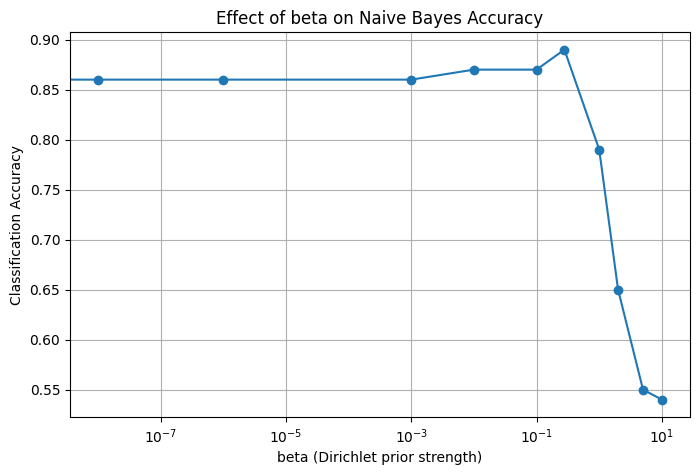

In [17]:
# beta around 0.2 to 0.4 gives the best result
betas = [0, 1e-8, 1e-6, 1e-3, 1e-2, 1e-1, 0.278,1, 2, 5, 10] #0.278 is added by myself
accuracies = []

for beta in betas:
    theta = train_multinomial_nb_map(X_train, y_train, beta)
    y_pred = predict_nb_mle(X_test, theta)
    acc = np.mean(y_pred == y_test)
    accuracies.append(acc)
    print(f"beta={beta}, accuracy={acc:.4f}")

plt.figure(figsize=(8,5))
plt.plot(betas, accuracies, marker="o")
plt.xscale("log")
plt.xlabel("beta (Dirichlet prior strength)")
plt.ylabel("Classification Accuracy")
plt.title("Effect of beta on Naive Bayes Accuracy")
plt.grid(True)
plt.show()

## 3.4 Study the Effect of Training Set Size


### Build Balanced Training Subsets of Size n per Class


In [18]:
def get_training_subset(base_train, hock_train, n):
  X = np.vstack([base_train[:n], hock_train[:n]])
  y = np.array([0]*n + [1]*n)
  return X, y

### Measure Test Accuracy Across Training Set Sizes


In [19]:
n_values = [1,5,10,15,20,25,30,35,40,45,50]
accuracies_n = []

beta = 0.1

for n in n_values:
  X_train_n, y_train_n = get_training_subset(base_train, hock_train, n)

  theta = train_multinomial_nb_map(X_train_n, y_train_n, beta)

  y_pred = predict_nb_mle(X_test, theta)
  acc = np.mean(y_pred == y_test)

  accuracies_n.append(acc)
  print(f"n={n}, accuracy={acc:.4f}")

n=1, accuracy=0.4600
n=5, accuracy=0.5900
n=10, accuracy=0.7500
n=15, accuracy=0.6000
n=20, accuracy=0.7100
n=25, accuracy=0.8100
n=30, accuracy=0.8100
n=35, accuracy=0.8300
n=40, accuracy=0.8400
n=45, accuracy=0.8800
n=50, accuracy=0.8700


### Plot the Training-Set-Size Learning Curve


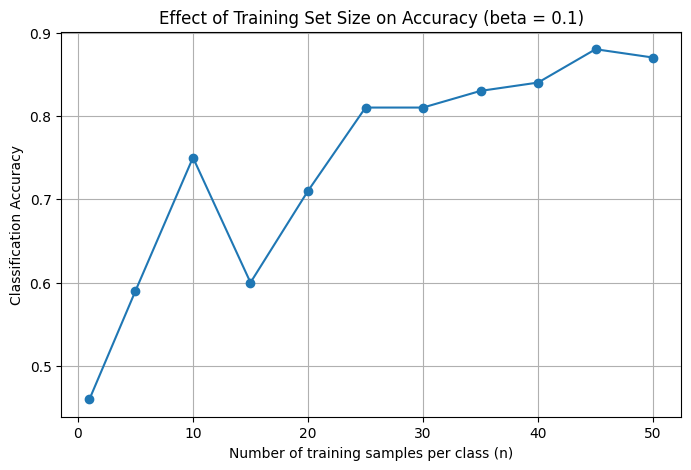

In [20]:
plt.figure(figsize=(8,5))
plt.plot(n_values, accuracies_n, marker="o")
plt.xlabel("Number of training samples per class (n)")
plt.ylabel("Classification Accuracy")
plt.title("Effect of Training Set Size on Accuracy (beta = 0.1)")
plt.grid(True)
plt.show()